# `HeleenaRobert/golf-swing-analysis`: end-to-end run

**Classification: Level A — the exact script ran end to end on its included video.** Reviewed at `0c551ae4d93cacd85a613b0b6d9d60aa2f333110` (2025-08-16). The result is an annotated video, not a measurement dataset.

,observed run
classification,Level A: exact repository script ran end to end on its included video
input,input/Reference_Swing_DTL.mp4
output,outputs/heleena/Reference_Swing_DTL_out_landmarks.mp4
exit_code,0
runtime_seconds,44.72
maximum_resident_memory_mb,750
frames,465
fps,30.0
duration_seconds,15.5
width,734


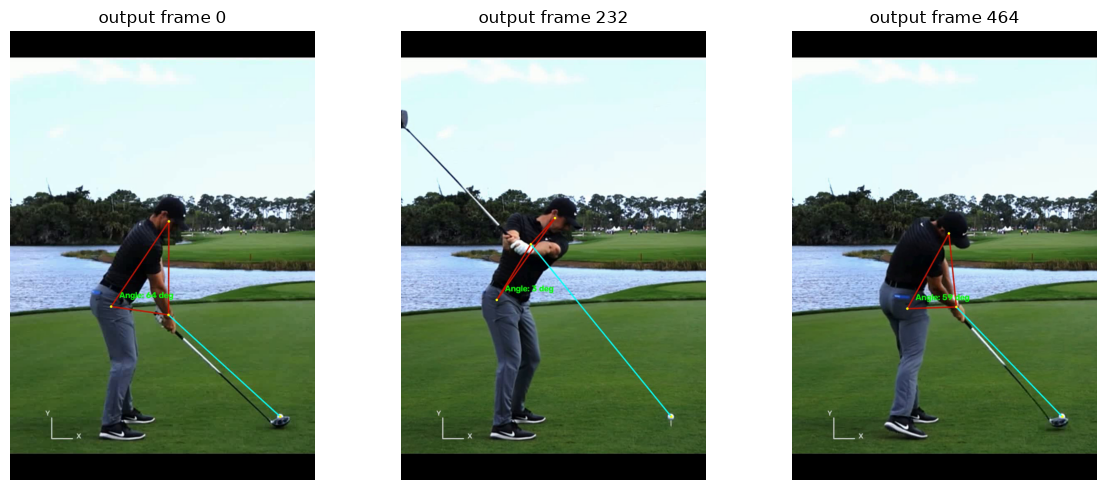

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
pd.set_option("display.max_colwidth", 100)

import cv2
out = ROOT / "outputs/heleena"
summary = json.loads((out / "summary.json").read_text())
display(pd.Series(summary, name="observed run").to_frame())

video = cv2.VideoCapture(str(out / "Reference_Swing_DTL_out_landmarks.mp4"))
frames = []
for index in (0, summary["frames"] // 2, summary["frames"] - 1):
    video.set(cv2.CAP_PROP_POS_FRAMES, index)
    ok, frame = video.read()
    if ok:
        frames.append((index, cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)))
video.release()

fig, axes = plt.subplots(1, len(frames), figsize=(12, 5))
for ax, (index, frame) in zip(np.atleast_1d(axes), frames):
    ax.imshow(frame); ax.set_title(f"output frame {index}"); ax.axis("off")
plt.tight_layout(); plt.show()

## Source and output audit

Every frame creates a new MediaPipe `Pose` context, extracts only right ear, right hip, and right wrist, draws the triangle among them, and displays the 2-D ear–hip–wrist angle at the hip. It also draws a wrist-to-ball line to the fixed pixel `(650, 927)`. That point is not detected, tracked, or calibrated. The script is implicitly down-the-line/right-side and has no view/handedness check.

The included 465-frame 734×1080, 30 fps video completed in 44.72 s (about 750 MB peak resident memory) and yielded a readable MPEG-4 output. There is no CSV/JSON, landmark confidence, missing-data record, event detector, phase label, club/shaft observation, trajectory, comparison function, or validation result. Recreating the pose object per frame also prevents MediaPipe's temporal tracking state from being used efficiently.

In [2]:
audit = pd.DataFrame([
    ("video → annotated video", "observed end to end"),
    ("pose", "3 MediaPipe landmarks consumed"),
    ("angle", "2-D ear–hip–wrist image angle"),
    ("ball", "fixed drawing coordinate, not a detection"),
    ("raw trajectory/confidence", "not exported"),
    ("events/club/comparison", "absent"),
    ("licence", "MIT file present"),
], columns=["area", "finding"])
display(audit)
print("EXECUTED_OK: Heleena end-to-end notebook")

,area,finding
0,video → annotated video,observed end to end
1,pose,3 MediaPipe landmarks consumed
2,angle,2-D ear–hip–wrist image angle
3,ball,"fixed drawing coordinate, not a detection"
4,raw trajectory/confidence,not exported
5,events/club/comparison,absent
6,licence,MIT file present


EXECUTED_OK: Heleena end-to-end notebook
